## Setup

We will create sample data because no external dataset is available.

In [ ]:
import math
import numpy as np
import pandas as pd
from scipy import stats

np.random.seed(42)
alpha = 0.05

def decision(p_value, alpha=0.05):
    if p_value < alpha:
        return "Reject H0"
    return "Fail to reject H0"

## 1. Levene Test for Equality of Variances

### Problem Statement

A logistics team wants to compare delivery-time variability between three
cities. Before using methods that assume equal variance, we test whether the
city variances are similar.

### Hypothesis

H0: All groups have equal variance.

H1: At least one group has different variance.

### Significance of the Test

Equal variance is an important assumption in many parametric comparison methods.
Levene test is useful because it is more robust than Bartlett test when data is
not perfectly normal.

In [ ]:
np.random.normal(32, 4, 35)
# normal(loc=32, scale=4, size=35)
# loc = mean, scale = std deviation, size = number of samples

array([33.98685661, 31.4469428 , 34.59075415, 38.09211943, 31.0633865 ,
       31.06345217, 38.31685126, 35.06973892, 30.12210246, 34.17024017,
       30.14632923, 30.13708099, 32.96784909, 24.34687902, 25.10032867,
       29.75084988, 27.94867552, 33.25698933, 28.3679037 , 26.35078519,
       37.86259508, 31.0968948 , 32.27011282, 26.30100726, 29.8224691 ,
       32.44369036, 27.39602569, 33.50279207, 29.59744524, 30.833225  ,
       29.59317355, 39.40911274, 31.9460111 , 27.76915628, 35.29017965])

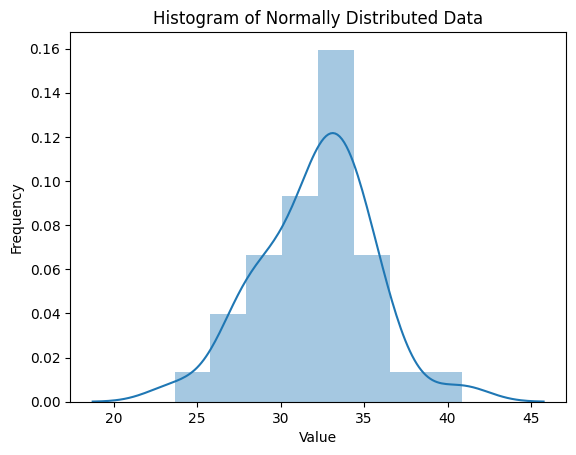

In [7]:
# Plot np.random.normal(32, 4, 35)

import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
# plt.figure(figsize=(10, 6))
sns.distplot(np.random.normal(32, 4, 35), kde=True)
plt.title('Histogram of Normally Distributed Data')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.show()

In [8]:
city_a = np.random.normal(32, 4, 35)
city_b = np.random.normal(35, 5, 35)
city_c = np.random.normal(33, 10, 35)

stat, p = stats.levene(city_a, city_b, city_c)

print("Levene statistic =", round(stat, 4))
print("p-value =", round(p, 4))
print("Decision:", decision(p))

Levene statistic = 14.4365
p-value = 0.0
Decision: Reject H0


In [ ]:
# If the p-value is below 0.05, the groups do not have the same spread.

In [9]:
city_a = np.random.normal(32, 4, 3500)
city_b = np.random.normal(35, 5, 3500)
city_c = np.random.normal(33, 10, 3500)

stat, p = stats.levene(city_a, city_b, city_c)

print("Levene statistic =", round(stat, 4))
print("p-value =", round(p, 4))
print("Decision:", decision(p))

Levene statistic = 1290.1338
p-value = 0.0
Decision: Reject H0


## 2. Bartlett Test for Equality of Variances

### Problem Statement

A lab measures impurity percentage using three machines. The team wants to know
whether the machines produce measurements with the same variance.

### Hypothesis

H0: All machine variances are equal.

H1: At least one machine variance is different.

### Significance of the Test

Bartlett test is powerful for normally distributed data. It is useful in quality
control and measurement system analysis.

In [10]:
machine_1 = np.random.normal(5.0, 0.4, 30)
machine_2 = np.random.normal(5.2, 0.4, 30)
machine_3 = np.random.normal(5.1, 0.9, 30)

stat, p = stats.bartlett(machine_1, machine_2, machine_3)

print("Bartlett statistic =", round(stat, 4))
print("p-value =", round(p, 4))
print("Decision:", decision(p))

Bartlett statistic = 23.6803
p-value = 0.0
Decision: Reject H0


In [11]:
# Bartlett is best used when the data is approximately normal. For heavily skewed data, Levene or Fligner-Killeen is usually safer.

## 3. Fligner-Killeen Test for Equality of Variances

### Problem Statement

Customer complaint resolution times are skewed. We want to compare whether the
variability is the same across three support teams.

### Hypothesis

H0: All groups have equal variance.

H1: At least one group has different variance.

### Significance of the Test

Fligner-Killeen is a non-parametric variance test. It is useful when data is
skewed or contains outliers.

In [12]:
team_a = np.random.gamma(shape=2.0, scale=2.0, size=40)
team_b = np.random.gamma(shape=2.0, scale=2.5, size=40)
team_c = np.random.gamma(shape=2.0, scale=4.0, size=40)

stat, p = stats.fligner(team_a, team_b, team_c)

print("Fligner-Killeen statistic =", round(stat, 4))
print("p-value =", round(p, 4))
print("Decision:", decision(p))

Fligner-Killeen statistic = 11.1679
p-value = 0.0038
Decision: Reject H0


In [13]:
# This checks variance equality without depending strongly on normality.

## 4. Anderson-Darling Test for Normality

### Problem Statement

A risk team wants to know whether daily portfolio returns follow a normal
distribution.

### Hypothesis

H0: The data follows the selected distribution.

H1: The data does not follow the selected distribution.

### Significance of the Test

Anderson-Darling is sensitive in the tails of a distribution. This matters in
risk, fraud, anomaly detection, and financial modeling.

In [14]:
returns = np.random.normal(loc=0.001, scale=0.02, size=80)

result = stats.anderson(returns, dist="norm")

print("Anderson-Darling statistic =", round(result.statistic, 4))
print("Critical values =", result.critical_values)
print("Significance levels =", result.significance_level)

critical_5 = result.critical_values[list(result.significance_level).index(5.0)]
if result.statistic > critical_5:
    print("Decision: Reject H0 at 5% level")
else:
    print("Decision: Fail to reject H0 at 5% level")

Anderson-Darling statistic = 0.4084
Critical values = [0.551 0.627 0.752 0.878 1.044]
Significance levels = [15.  10.   5.   2.5  1. ]
Decision: Fail to reject H0 at 5% level


In [15]:
# Unlike many tests, Anderson-Darling is usually interpreted using critical values instead of a direct p-value.

## 5. D'Agostino-Pearson Normality Test

### Problem Statement

A modeler checks whether model residuals look normally distributed by examining
both skewness and kurtosis together.

### Hypothesis

H0: The data is normally distributed.

H1: The data is not normally distributed.

### Significance of the Test

This test is useful for validating regression assumptions and checking whether
errors are symmetric and not too heavy-tailed.

In [16]:
residuals = np.random.normal(loc=0, scale=1, size=100)

stat, p = stats.normaltest(residuals)

print("D'Agostino-Pearson statistic =", round(stat, 4))
print("p-value =", round(p, 4))
print("Decision:", decision(p))

D'Agostino-Pearson statistic = 1.3651
p-value = 0.5053
Decision: Fail to reject H0


In [17]:
# The test combines skewness and kurtosis into one normality test.

## 6. Jarque-Bera Test

### Problem Statement

An analyst wants to know whether sales forecast errors are normally distributed.

### Hypothesis

H0: The data has normal skewness and kurtosis.

H1: The data does not have normal skewness and kurtosis.

### Significance of the Test

Jarque-Bera is widely used in econometrics and forecasting to check normality of
errors.

In [18]:
forecast_errors = np.random.standard_t(df=6, size=120)

stat, p = stats.jarque_bera(forecast_errors)

print("Jarque-Bera statistic =", round(stat, 4))
print("p-value =", round(p, 4))
print("Decision:", decision(p))

Jarque-Bera statistic = 12.4925
p-value = 0.0019
Decision: Reject H0


In [19]:
# The test focuses on whether skewness and kurtosis match what we expect from a normal distribution.

## 7. Kendall Tau Correlation Test

### Problem Statement

A product team ranks customers by satisfaction and by renewal likelihood. We
test whether the two rankings are associated.

### Hypothesis

H0: There is no ordinal association between the two variables.

H1: There is a significant ordinal association between the two variables.

### Significance of the Test

Kendall Tau is useful for ordinal data and ranked data. It is often more stable
than simple correlation when sample size is small or many ranks are close.

In [ ]:
satisfaction_rank = np.arange(1, 31) # satisfaction_rank - 1 to 30
renewal_rank = satisfaction_rank + np.random.randint(-5, 6, size=30) # renewal_rank is satisfaction_rank with some random noise added

stat, p = stats.kendalltau(satisfaction_rank, renewal_rank)

print("Kendall tau =", round(stat, 4))
print("p-value =", round(p, 4))
print("Decision:", decision(p))

Kendall tau = 0.8136
p-value = 0.0
Decision: Reject H0


In [21]:
# Kendall Tau checks whether larger values of one ranked variable generally go with larger values of another ranked variable.

## 8. Fisher's Exact Test

### Problem Statement

A small medical pilot study compares recovery between treatment and control
groups. The sample size is small, so chi-square approximation may not be ideal.

### Hypothesis

H0: Treatment and recovery are independent.

H1: Treatment and recovery are associated.

### Significance of the Test

Fisher's exact test is important for small 2 x 2 categorical tables where
chi-square assumptions are weak.

In [22]:
table = np.array([
    [9, 1],
    [4, 6]
])

odds_ratio, p = stats.fisher_exact(table)

print("Contingency table:")
print(table)
print("Odds ratio =", round(odds_ratio, 4))
print("p-value =", round(p, 4))
print("Decision:", decision(p))

Contingency table:
[[9 1]
 [4 6]]
Odds ratio = 13.5
p-value = 0.0573
Decision: Fail to reject H0


In [23]:
# The test gives an exact p-value for a small 2 x 2 table.

## 9. McNemar Test

### Problem Statement

Two fraud models are tested on the same transactions. We want to check whether
the new model changes correct/incorrect outcomes compared with the old model.

### Hypothesis

H0: The two paired classifiers have the same error pattern.

H1: The two paired classifiers have different error patterns.

### Significance of the Test

McNemar test is useful when comparing two classifiers on exactly the same test
cases.

In [24]:
# rows = old model result, columns = new model result
# order: correct, incorrect
paired_table = np.array([
    [65, 7],
    [19, 9]
])

b = paired_table[0, 1]
c = paired_table[1, 0]

result = stats.binomtest(k=min(b, c), n=b + c, p=0.5, alternative="two-sided")
p = result.pvalue

print("Paired table:")
print(paired_table)
print("Discordant pairs =", b, c)
print("p-value =", round(p, 4))
print("Decision:", decision(p))

Paired table:
[[65  7]
 [19  9]]
Discordant pairs = 7 19
p-value = 0.029
Decision: Reject H0


In [25]:
# Only the cases where the two models disagree are used for the test.

## 10. Cochran's Q Test

### Problem Statement

The same customers are shown three ad designs. For each design, response is
recorded as clicked or not clicked. We test whether click behavior differs
across designs.

### Hypothesis

H0: The response rate is the same for all related treatments.

H1: At least one related treatment has a different response rate.

### Significance of the Test

Cochran's Q is an extension of McNemar's idea for more than two related binary
conditions.

In [26]:
responses = pd.DataFrame({
    "Ad_A": [1,0,1,1,0,1,0,1,1,0,1,0],
    "Ad_B": [1,1,1,0,0,1,0,1,0,0,1,1],
    "Ad_C": [0,1,1,0,1,1,0,0,0,1,1,1]
})

x = responses.to_numpy()
n, k = x.shape
col_sum = x.sum(axis=0)
row_sum = x.sum(axis=1)

q_num = (k - 1) * (k * np.sum(col_sum ** 2) - np.sum(col_sum) ** 2)
q_den = k * np.sum(row_sum) - np.sum(row_sum ** 2)
q_stat = q_num / q_den
p = stats.chi2.sf(q_stat, df=k - 1)

display(responses.head())
print("Cochran Q statistic =", round(q_stat, 4))
print("p-value =", round(p, 4))
print("Decision:", decision(p))

,Ad_A,Ad_B,Ad_C
0,1,1,0
1,0,1,1
2,1,1,1
3,1,0,0
4,0,0,1


Cochran Q statistic = 0.0
p-value = 1.0
Decision: Fail to reject H0


In [ ]:
# The same subjects must be measured under all binary conditions.

## 11. Mood's Median Test

### Problem Statement

Three stores have skewed basket values. We want to know whether their medians
are different.

### Hypothesis

H0: All groups have the same median.

H1: At least one group has a different median.

### Significance of the Test

Mood's median test is useful when the focus is the median rather than the mean,
especially for skewed business data.

In [27]:
store_a = np.random.gamma(3, 100, 35)
store_b = np.random.gamma(3, 120, 35)
store_c = np.random.gamma(3, 150, 35)

stat, p, grand_median, table = stats.median_test(store_a, store_b, store_c)

print("Grand median =", round(grand_median, 4))
print("Contingency table:")
print(table)
print("Mood median statistic =", round(stat, 4))
print("p-value =", round(p, 4))
print("Decision:", decision(p))

Grand median = 390.5647
Contingency table:
[[12 18 22]
 [23 17 13]]
Mood median statistic = 5.791
p-value = 0.0553
Decision: Fail to reject H0


In [28]:
# The test counts how many observations from each group fall above and below the overall median.

## 12. Ansari-Bradley Test

### Problem Statement

Two sensors have similar average readings. We test whether one sensor has more
spread or variability than the other.

### Hypothesis

H0: The two distributions have the same scale or spread.

H1: The two distributions have different scale or spread.

### Significance of the Test

This non-parametric test helps compare variability between two independent
groups without relying fully on normality.

In [29]:
sensor_a = np.random.normal(100, 4, 35)
sensor_b = np.random.normal(100, 9, 35)

stat, p = stats.ansari(sensor_a, sensor_b)

print("Ansari-Bradley statistic =", round(stat, 4))
print("p-value =", round(p, 4))
print("Decision:", decision(p))

Ansari-Bradley statistic = 759.0
p-value = 0.0022
Decision: Reject H0


In [30]:
# The test focuses on differences in spread, not differences in center.

## 13. Brunner-Munzel Test

### Problem Statement

Two customer segments have non-normal satisfaction scores and may have unequal
variance. We test whether one segment tends to have higher scores.

### Hypothesis

H0: A randomly selected value from either group is equally likely to be larger.

H1: One group tends to have larger values than the other.

### Significance of the Test

Brunner-Munzel is a useful alternative to Mann-Whitney when distributions have
unequal shapes or variances.

In [31]:
segment_a = np.random.gamma(3, 2, 45)
segment_b = np.random.gamma(4, 2.5, 45)

stat, p = stats.brunnermunzel(segment_a, segment_b)

print("Brunner-Munzel statistic =", round(stat, 4))
print("p-value =", round(p, 4))
print("Decision:", decision(p))

Brunner-Munzel statistic = 5.5185
p-value = 0.0
Decision: Reject H0


In [32]:
# This test compares stochastic dominance, meaning whether values from one group tend to exceed values from another group.

## 14. Wald-Wolfowitz Runs Test

### Problem Statement

A call center tracks whether each ticket is resolved within SLA. We test whether
the success/failure sequence appears random.

### Hypothesis

H0: The sequence is random.

H1: The sequence is not random.

### Significance of the Test

Runs testing is useful for checking process stability, randomness, and whether
events are clustering over time.

In [33]:
sequence = np.array([1,1,0,1,0,0,1,1,1,0,0,1,0,1,1,0,0,0,1,1,0,1,0,0,1])

n1 = np.sum(sequence == 1)
n2 = np.sum(sequence == 0)
runs = 1 + np.sum(sequence[1:] != sequence[:-1])

mean_runs = 1 + (2 * n1 * n2) / (n1 + n2)
var_runs = (
    (2 * n1 * n2 * (2 * n1 * n2 - n1 - n2))
    / (((n1 + n2) ** 2) * (n1 + n2 - 1))
)
z = (runs - mean_runs) / math.sqrt(var_runs)
p = 2 * (1 - stats.norm.cdf(abs(z)))

print("Number of runs =", runs)
print("z statistic =", round(z, 4))
print("p-value =", round(p, 4))
print("Decision:", decision(p))

Number of runs = 15
z statistic = 0.6221
p-value = 0.5339
Decision: Fail to reject H0


In [34]:
# Too few runs may mean clustering. Too many runs may mean unnatural alternation.

## 15. Grubbs Test for One Outlier

### Problem Statement

A manufacturing dataset has one very high reading. We test whether the most
extreme value can be treated as a statistically significant outlier.

### Hypothesis

H0: There is no outlier in the data.

H1: There is one significant outlier in the data.

### Significance of the Test

Outlier testing is important before building models, dashboards, and control
charts because one extreme value can distort the analysis.

In [35]:
measurements = np.array([10.2, 10.5, 9.8, 10.1, 10.4, 9.9, 10.3, 10.0, 10.2, 14.8])

n = len(measurements)
mean_value = measurements.mean()
std_value = measurements.std(ddof=1)
g_stat = np.max(np.abs(measurements - mean_value)) / std_value

t_critical = stats.t.ppf(1 - alpha / (2 * n), n - 2)
g_critical = ((n - 1) / math.sqrt(n)) * math.sqrt(t_critical ** 2 / (n - 2 + t_critical ** 2))

print("Grubbs statistic =", round(g_stat, 4))
print("Critical value =", round(g_critical, 4))

if g_stat > g_critical:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")

Grubbs statistic = 2.8156
Critical value = 2.29
Decision: Reject H0


In [36]:
# Grubbs test is designed for detecting one outlier in approximately normal data.

## 16. Tukey HSD Post-Hoc Test

### Problem Statement

After comparing several training methods, the analyst wants to know exactly
which pairs of methods differ.

### Hypothesis

H0: The selected pair of group means is equal.

H1: The selected pair of group means is different.

### Significance of the Test

ANOVA can say that at least one group differs, but it does not identify which
groups differ. Tukey HSD performs pairwise comparisons while controlling the
overall error rate.

In [37]:
method_a = np.random.normal(72, 5, 25)
method_b = np.random.normal(76, 5, 25)
method_c = np.random.normal(84, 5, 25)

result = stats.tukey_hsd(method_a, method_b, method_c)

print(result)

Tukey's HSD Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -3.835     0.086    -8.092     0.423
 (0 - 2)    -12.775     0.000   -17.032    -8.517
 (1 - 0)      3.835     0.086    -0.423     8.092
 (1 - 2)     -8.940     0.000   -13.198    -4.682
 (2 - 0)     12.775     0.000     8.517    17.032
 (2 - 1)      8.940     0.000     4.682    13.198



In [38]:
# Use Tukey HSD after finding evidence of group differences when you need pairwise comparisons.

## Quick Selection Guide

| Situation | New test to use |
| --- | --- |
| Compare variances with moderate robustness | Levene test |
| Compare variances when data is normal | Bartlett test |
| Compare variances with skewed data/outliers | Fligner-Killeen test |
| Normality check with tail sensitivity | Anderson-Darling test |
| Normality check using skewness and kurtosis | D'Agostino-Pearson or Jarque-Bera |
| Association between ranked variables | Kendall Tau |
| Small 2 x 2 categorical table | Fisher's exact test |
| Two paired classifiers or before/after binary outcomes | McNemar test |
| More than two related binary treatments | Cochran's Q test |
| Compare medians across groups | Mood's median test |
| Compare spread of two independent groups | Ansari-Bradley test |
| Compare two non-normal groups with unequal variance | Brunner-Munzel test |
| Check randomness in a sequence | Wald-Wolfowitz runs test |
| Test one possible outlier | Grubbs test |
| Find which group pairs differ after ANOVA | Tukey HSD post-hoc test |

## Final Note

No test should be chosen only by name. Choose it based on the data type,
dependency structure, number of groups, assumptions, and the business question.